# WATERWATCH AI 💧🤖
## Phase 2 & Phase 4: Data Cleaning, Preprocessing & Train-Test Splitting
**Role:** Member 1 – Data & ML Engineer  
**Project:** Explainable AI-Based Water Potability Prediction and Community Risk Monitoring System  

---

### Objectives & Core Principles
1. **Missing-Value Strategy:** Median imputation using Scikit-Learn `SimpleImputer` (preserves records without distortion from skewed tails).
2. **Outlier Investigation (IQR Method):** Identify and quantify outliers without deleting valid environmental contamination data.
3. **Data Leakage Prevention:** Feature-target separation and train-test splitting are performed **before** fitting imputers and scalers.
4. **Stratified Splitting (80/20):** Guarantees that training (2,620) and testing (656) partitions maintain the exact 61:39 class ratio.
5. **Scikit-Learn Pipeline:** Encapsulates median imputation and feature scaling (`StandardScaler`) for clean deployment and handover to Member 3.

### 1. Library Imports & Data Loading

In [10]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

# Load raw dataset
import os
# Robust dataset path: checks data/raw/ before falling back
DATA_PATH = '../data/raw/water_potability.csv' if os.path.exists('../data/raw/water_potability.csv') else ('data/raw/water_potability.csv' if os.path.exists('data/raw/water_potability.csv') else '../data/water_potability.csv')
df = pd.read_csv(DATA_PATH)
print(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")

Loaded dataset: 3276 rows, 10 columns


### 2. Duplicate Detection & Data-Type Validation

In [11]:
# Duplicate check
duplicates = df.duplicated().sum()
print(f"Duplicate records: {duplicates}")
assert duplicates == 0, "Duplicate rows detected!"

# Validate column types
print("\nColumn Data Types:")
print(df.dtypes)
assert all(df.drop(columns=['Potability']).dtypes == 'float64'), "All input features must be float64!"
assert df['Potability'].dtype == 'int64', "Target variable 'Potability' must be int64!"

Duplicate records: 0

Column Data Types:
ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object


### 3. Outlier Investigation Using the IQR Method
- Interquartile Range: $IQR = Q3 - Q1$
- Lower Bound: $Q1 - 1.5 \times IQR$
- Upper Bound: $Q3 + 1.5 \times IQR$
- **Policy:** Outliers are quantified and logged below, but **retained** because they reflect valid chemical pollution/risk extremes.

In [12]:
features = df.columns.drop('Potability')
outlier_records = []

for col in features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
    outlier_records.append({
        'Feature': col,
        'Q1 (25%)': round(q1, 2),
        'Q3 (75%)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': len(outliers),
        'Outlier %': round(len(outliers) / len(df) * 100, 2)
    })

outlier_summary_df = pd.DataFrame(outlier_records)
print("=== IQR OUTLIER SUMMARY TABLE ===")
display(outlier_summary_df)

=== IQR OUTLIER SUMMARY TABLE ===


,Feature,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,ph,6.09,8.06,1.97,3.14,11.02,46,1.40
1,Hardness,176.85,216.67,39.82,117.13,276.39,83,2.53
2,Solids,15666.69,27332.76,11666.07,-1832.42,44831.87,47,1.43
3,Chloramines,6.13,8.11,1.99,3.15,11.10,61,1.86
4,Sulfate,307.70,359.95,52.25,229.32,438.33,41,1.25
5,Conductivity,365.73,481.79,116.06,191.65,655.88,11,0.34
6,Organic_carbon,12.07,16.56,4.49,5.33,23.30,25,0.76
7,Trihalomethanes,55.84,77.34,21.49,23.61,109.58,33,1.01
8,Turbidity,3.44,4.50,1.06,1.85,6.09,19,0.58


### 4. Feature and Target Separation
- $X$ = 9 water-quality input features
- $y$ = `Potability` binary target variable (0 or 1)

In [13]:
X = df.drop(columns=['Potability'])
y = df['Potability']

print(f"X shape (Input Features): {X.shape}")
print(f"y shape (Target Label):   {y.shape}")
print(f"Features: {list(X.columns)}")

X shape (Input Features): (3276, 9)
y shape (Target Label):   (3276,)
Features: ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']


### 5. Stratified Train-Test Splitting (80% Train, 20% Test)
- **Train size:** 80% (2,620 samples)
- **Test size:** 20% (656 samples)
- **Fixed random state:** `random_state=42` for exact reproducibility
- **Stratification:** `stratify=y` guarantees identical class proportions in both sets

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training partition shape: {X_train.shape}")
print(f"Testing partition shape:  {X_test.shape}\n")

train_class_ratio = y_train.value_counts(normalize=True) * 100
test_class_ratio = y_test.value_counts(normalize=True) * 100

split_dist = pd.DataFrame({
    'Train Count': y_train.value_counts(),
    'Train Ratio (%)': train_class_ratio.round(2),
    'Test Count': y_test.value_counts(),
    'Test Ratio (%)': test_class_ratio.round(2)
}, index=[0, 1])
split_dist.index.name = 'Potability Class'
print("=== STRATIFIED CLASS BALANCE VERIFICATION ===")
display(split_dist)

Training partition shape: (2620, 9)
Testing partition shape:  (656, 9)

=== STRATIFIED CLASS BALANCE VERIFICATION ===


,Train Count,Train Ratio (%),Test Count,Test Ratio (%)
Potability Class,,,,
0,1598,60.99,400,60.98
1,1022,39.01,256,39.02


### 6. Scikit-Learn Preprocessing Pipeline (Median Imputation + Scaling)
- **Data Leakage Protection:**
  - `preprocessor.fit_transform(X_train)`: Learns the training medians and scaling parameters **only** from `X_train`.
  - `preprocessor.transform(X_test)`: Applies those learned training parameters to `X_test` with **zero data leakage**.

In [15]:
# Define reusable preprocessing pipeline
preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Fit strictly on X_train, then transform both
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Verify zero missing values remain
assert np.isnan(X_train_processed).sum() == 0, "Missing values remain in training set!"
assert np.isnan(X_test_processed).sum() == 0, "Missing values remain in testing set!"

print("✓ Preprocessing Pipeline successfully fitted.")
print("✓ Missing values after imputation: 0")
print(f"✓ X_train_processed shape: {X_train_processed.shape}")
print(f"✓ X_test_processed shape:  {X_test_processed.shape}\n")

print("--- Learned Training Medians for Imputation ---")
for col, med in zip(X.columns, preprocessor.named_steps['imputer'].statistics_):
    print(f"  - {col:16s}: {med:.2f}")

✓ Preprocessing Pipeline successfully fitted.
✓ Missing values after imputation: 0
✓ X_train_processed shape: (2620, 9)
✓ X_test_processed shape:  (656, 9)

--- Learned Training Medians for Imputation ---
  - ph              : 7.04
  - Hardness        : 196.93
  - Solids          : 20866.34
  - Chloramines     : 7.12
  - Sulfate         : 333.07
  - Conductivity    : 424.94
  - Organic_carbon  : 14.21
  - Trihalomethanes : 66.57
  - Turbidity       : 3.97


### 7. Verification of Standardized Scale
Checking mean and standard deviation of scaled training features (expecting mean $\approx 0$ and std $\approx 1$):

In [16]:
scaled_check_df = pd.DataFrame(X_train_processed, columns=X.columns)
print("=== SCALED TRAINING DATASET CHECK (Mean ≈ 0, Std ≈ 1) ===")
display(scaled_check_df.describe().T[['mean', 'std', 'min', 'max']].round(4))

=== SCALED TRAINING DATASET CHECK (Mean ≈ 0, Std ≈ 1) ===


,mean,std,min,max
ph,0.0,1.0002,-4.6630,4.3968
Hardness,-0.0,1.0002,-4.5689,3.8798
Solids,0.0,1.0002,-2.4624,4.4916
Chloramines,0.0,1.0002,-4.2306,3.7072
Sulfate,0.0,1.0002,-5.6521,4.0647
Conductivity,0.0,1.0002,-3.0451,4.0212
Organic_carbon,-0.0,1.0002,-3.6629,3.8635
Trihalomethanes,-0.0,1.0002,-4.1430,3.6623
Turbidity,-0.0,1.0002,-3.1807,3.5443


---
## Phase 8: Advanced Missing-Value Imputation Comparison Study
**Role:** Member 1 – Data & ML Engineer  
**Task:** Compare baseline Median Imputation with KNN Imputation (k=5) and Iterative Imputation (MICE with Bayesian Ridge).

### Imputation Paradigms Evaluated:
1. **Median Imputation (Baseline):** Univariate replacement using training set column medians. Fast and outlier-robust, but ignores multivariate correlations and attenuates variance.
2. **KNN Imputation (k=5):** Non-parametric multivariate imputation based on Euclidean distance among the 5 nearest neighbors. **Scaling is mathematically mandatory** before distance computation to prevent high-magnitude features (e.g. `Solids` ~ 20,000) from dominating over normalized features (e.g. `ph` ~ 7).
3. **Iterative Imputation (MICE):** Multivariate round-robin regression modeling each missing feature as a function of all remaining features using Bayesian Ridge. Standardizing prior to regression guarantees isotropic L2 regularization across variables.

> **Data Leakage Safeguard:** All imputers and scalers are strictly embedded in `sklearn.pipeline.Pipeline` objects and fitted exclusively on training splits ($X_{train}$), ensuring zero test leakage during holdout testing and cross-validation.

In [17]:
# Phase 8: Advanced Missing-Value Imputation Pipeline Comparison
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# Load pre-computed comparison metrics
imputation_results_path = '../results/metrics/imputation_comparison.csv' if os.path.exists('../results/metrics/imputation_comparison.csv') else 'results/metrics/imputation_comparison.csv'
imputation_df = pd.read_csv(imputation_results_path)
print('=== COMPLETE IMPUTATION COMPARISON BENCHMARK TABLE ===')
display(imputation_df)


=== COMPLETE IMPUTATION COMPARISON BENCHMARK TABLE ===


,Imputation Method,Classifier,Accuracy,Precision (Macro),Precision (Weighted),Recall (Non-Potable / 0),Recall (Potable / 1),Recall (Macro),F1-Score (Macro),F1-Score (Weighted),ROC-AUC,Dangerous Errors (Actual 0 -> Pred 1),Dangerous Error Rate (%),5-Fold CV Accuracy Mean,5-Fold CV Accuracy Std,5-Fold CV F1-Macro Mean,5-Fold CV F1-Macro Std
0,Median Imputation (Baseline),Dummy Classifier,0.6098,0.3049,0.3718,1.0000,0.0000,0.5000,0.3788,0.4619,0.5000,0,0.00,0.6099,0.0009,0.3789,0.0004
1,Median Imputation (Baseline),Gaussian Naive Bayes,0.6143,0.5733,0.5859,0.8875,0.1875,0.5375,0.5062,0.5569,0.6090,45,11.25,0.6275,0.0074,0.5393,0.0129
2,Median Imputation (Baseline),Decision Tree,0.6311,0.6029,0.6126,0.8675,0.2617,0.5646,0.5489,0.5912,0.6011,53,13.25,0.6298,0.0095,0.5192,0.0307
3,Median Imputation (Baseline),Random Forest,0.6662,0.6561,0.6598,0.8800,0.3320,0.6060,0.5999,0.6356,0.6492,48,12.00,0.6809,0.0157,0.6157,0.0248
4,KNN Imputation (k=5),Gaussian Naive Bayes,0.6159,0.5765,0.5886,0.8875,0.1914,0.5395,0.5090,0.5593,0.6083,45,11.25,0.6279,0.0100,0.5353,0.0182
5,KNN Imputation (k=5),Decision Tree,0.6311,0.6081,0.6151,0.9025,0.2070,0.5548,0.5268,0.5756,0.5852,39,9.75,0.6336,0.0132,0.5239,0.0332
6,KNN Imputation (k=5),Random Forest,0.6524,0.6361,0.6420,0.8750,0.3047,0.5898,0.5803,0.6185,0.6630,50,12.50,0.6683,0.0091,0.6039,0.0108
7,Iterative Imputation (MICE),Gaussian Naive Bayes,0.6143,0.5733,0.5859,0.8875,0.1875,0.5375,0.5062,0.5569,0.6082,45,11.25,0.6271,0.0095,0.5382,0.0150
8,Iterative Imputation (MICE),Decision Tree,0.6326,0.6055,0.6149,0.8700,0.2617,0.5659,0.5501,0.5924,0.5917,52,13.00,0.6347,0.0095,0.5317,0.0361
9,Iterative Imputation (MICE),Random Forest,0.6784,0.6790,0.6788,0.9000,0.3320,0.6160,0.6098,0.6457,0.6492,40,10.00,0.6775,0.0099,0.6138,0.0199


### Visualizing Performance Across Imputation Strategies
The following charts evaluate accuracy, macro F1, and dangerous false-positive rates (Actual 0 -> Predicted 1) across the three imputation strategies.

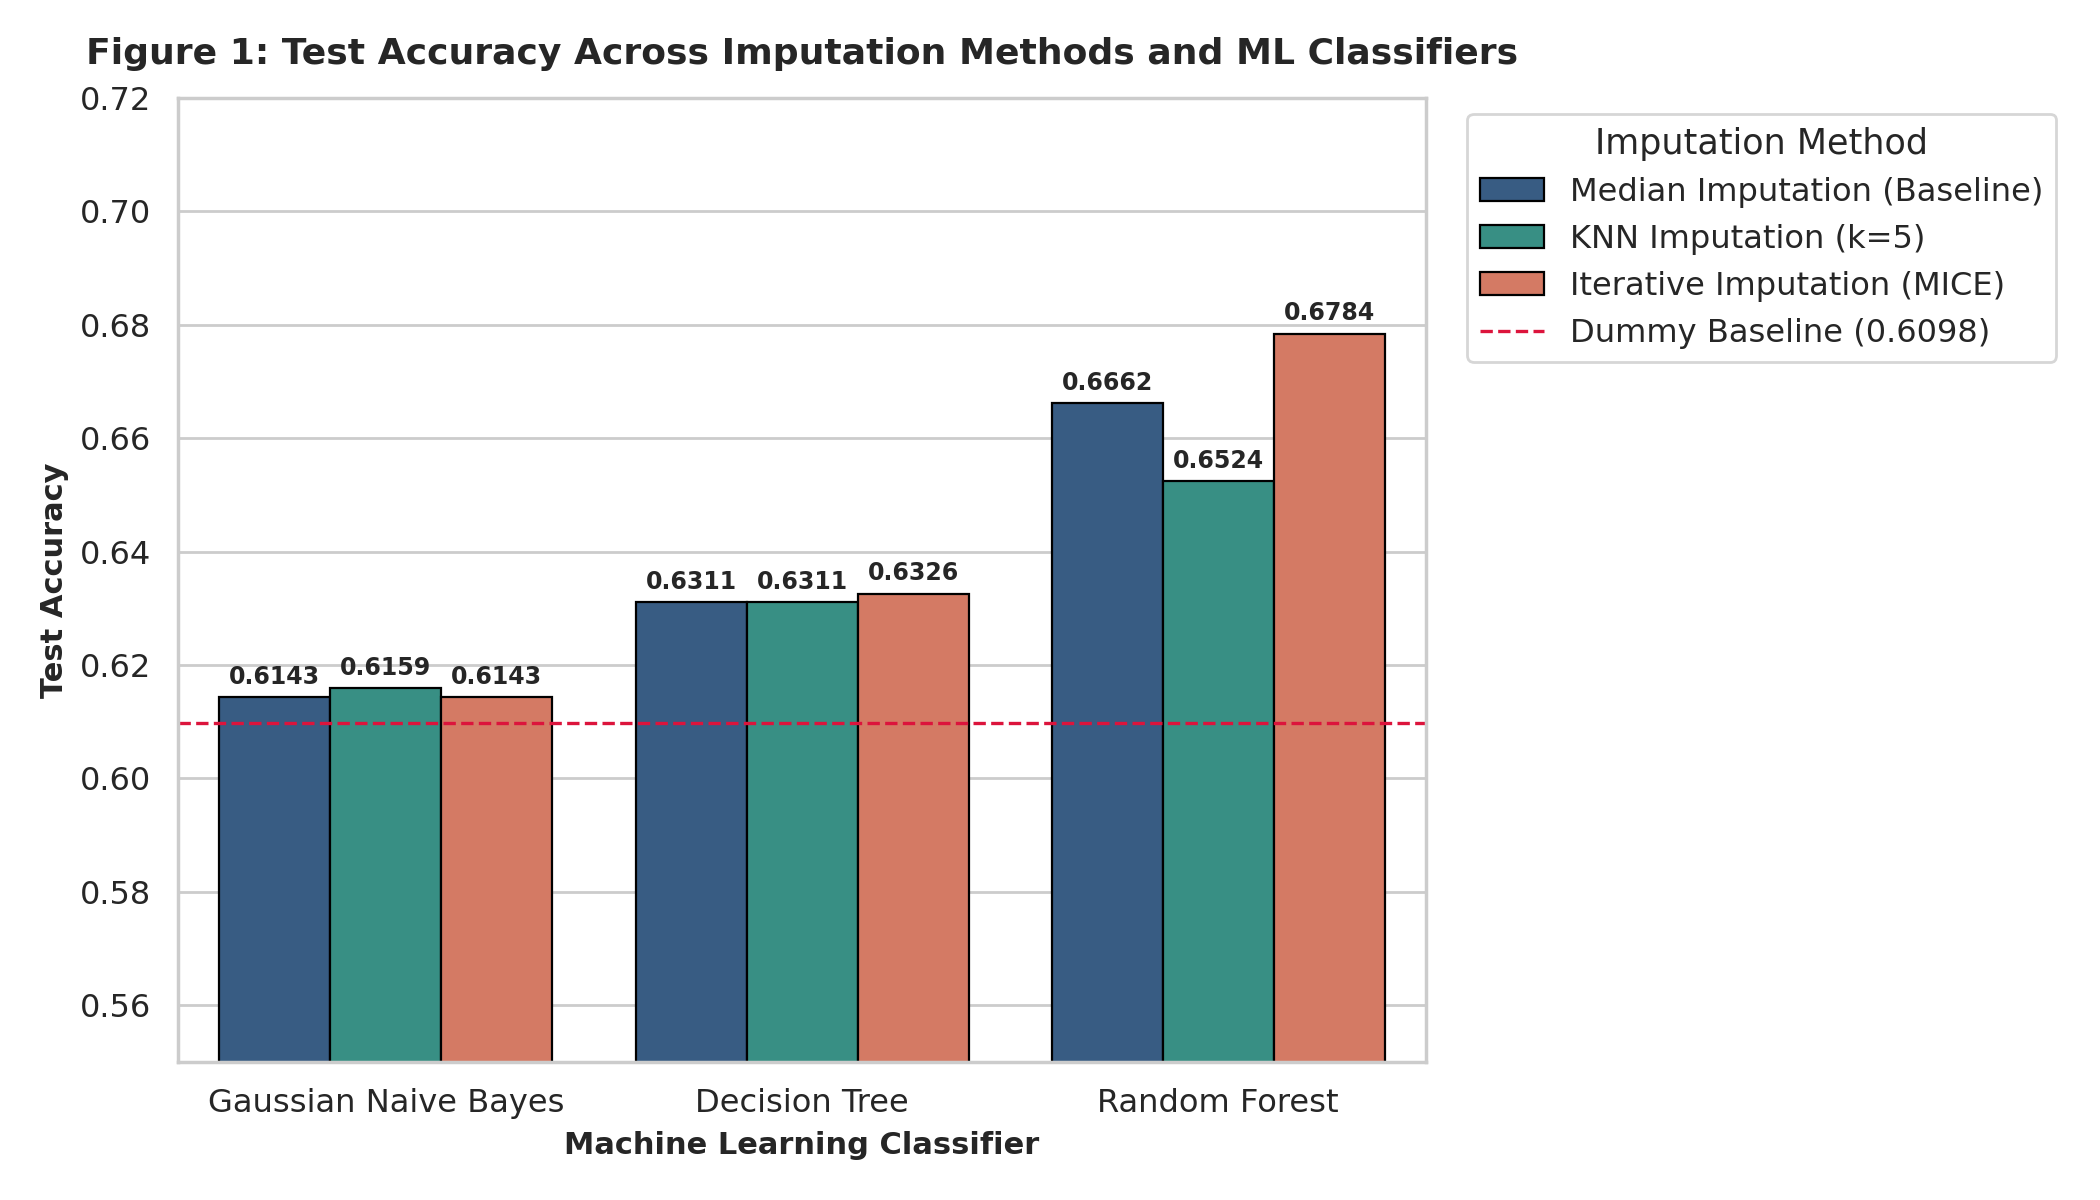

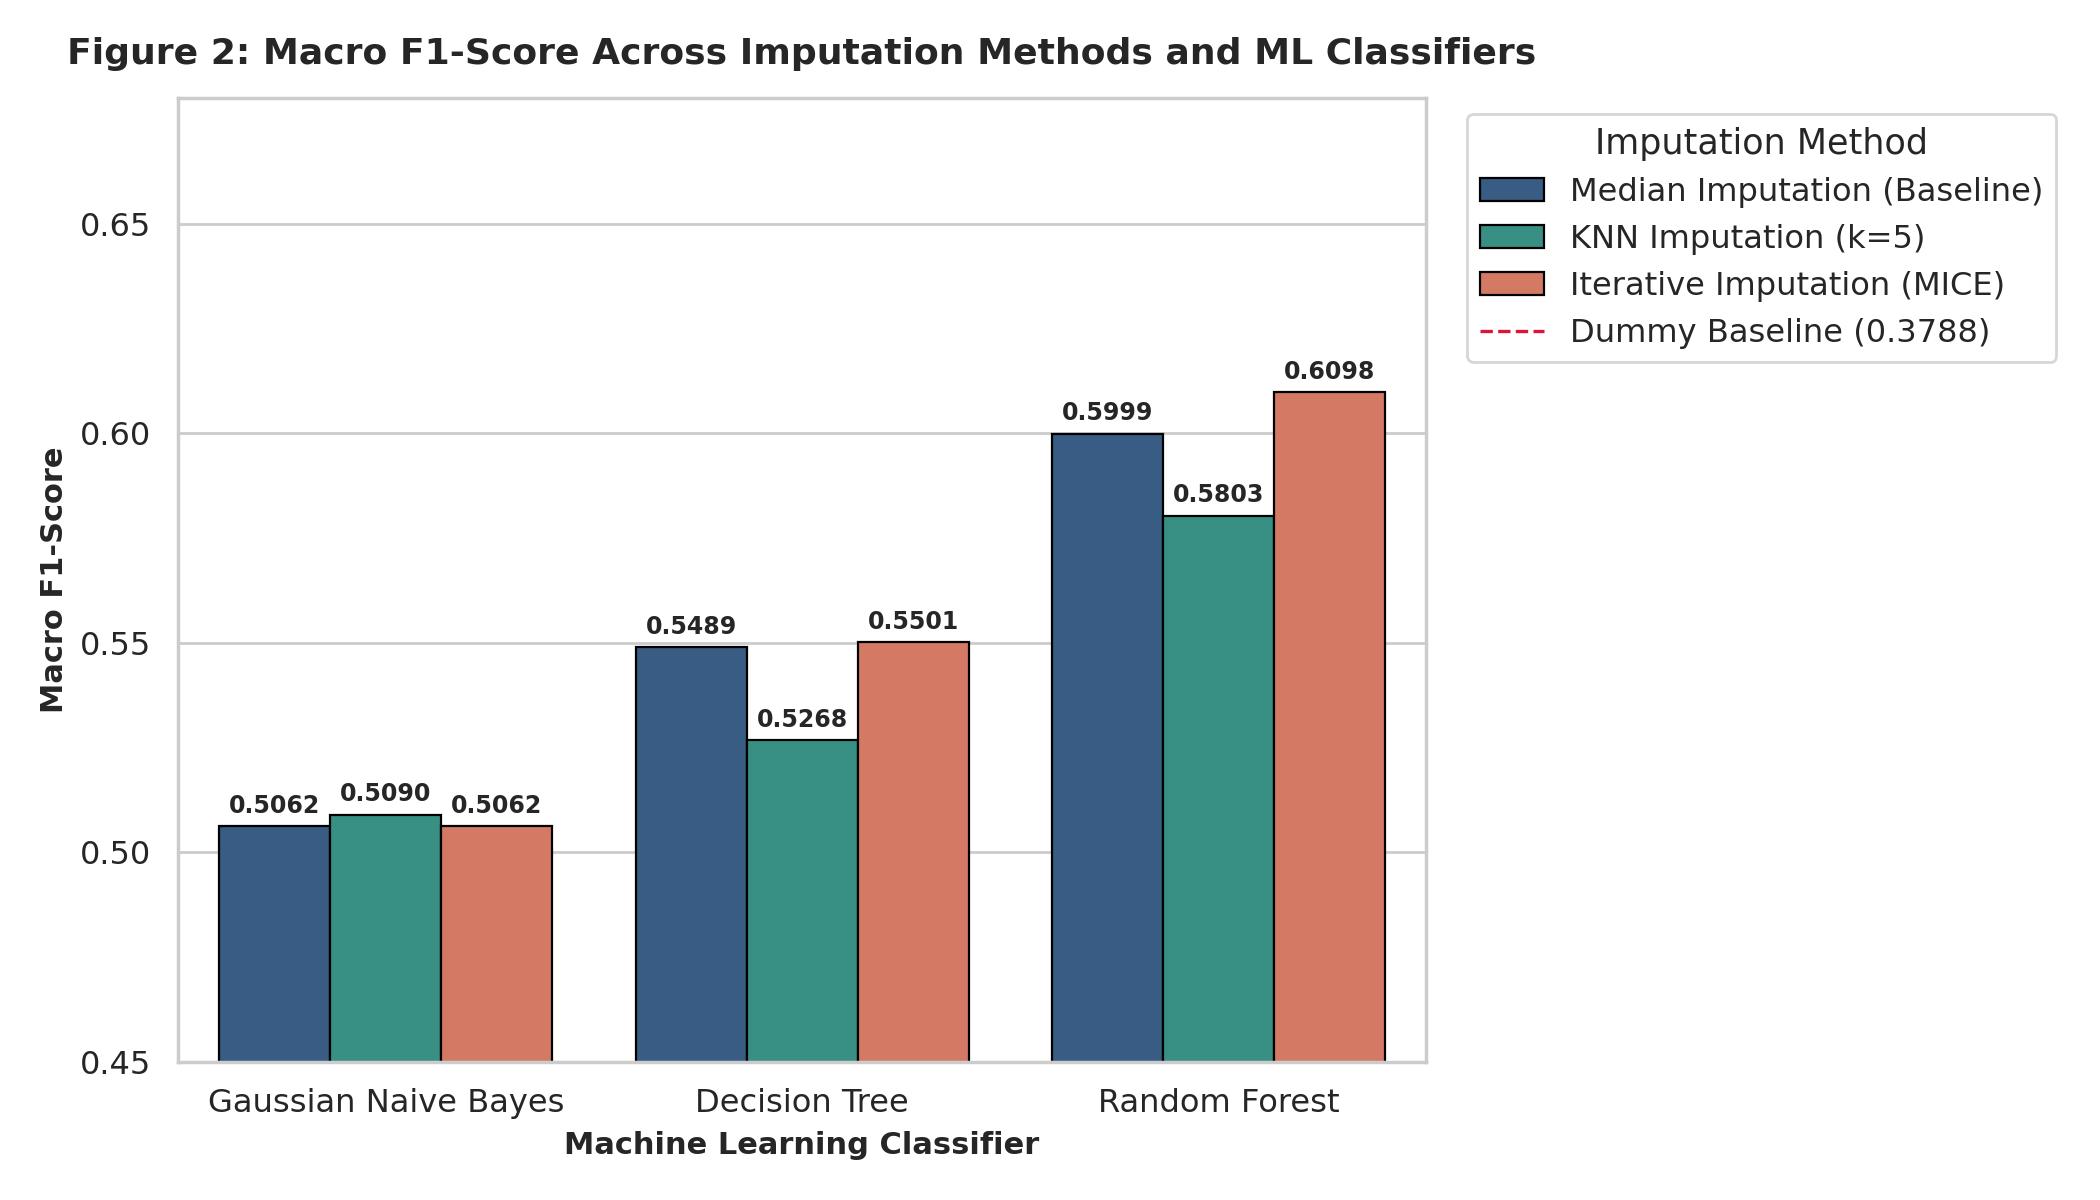

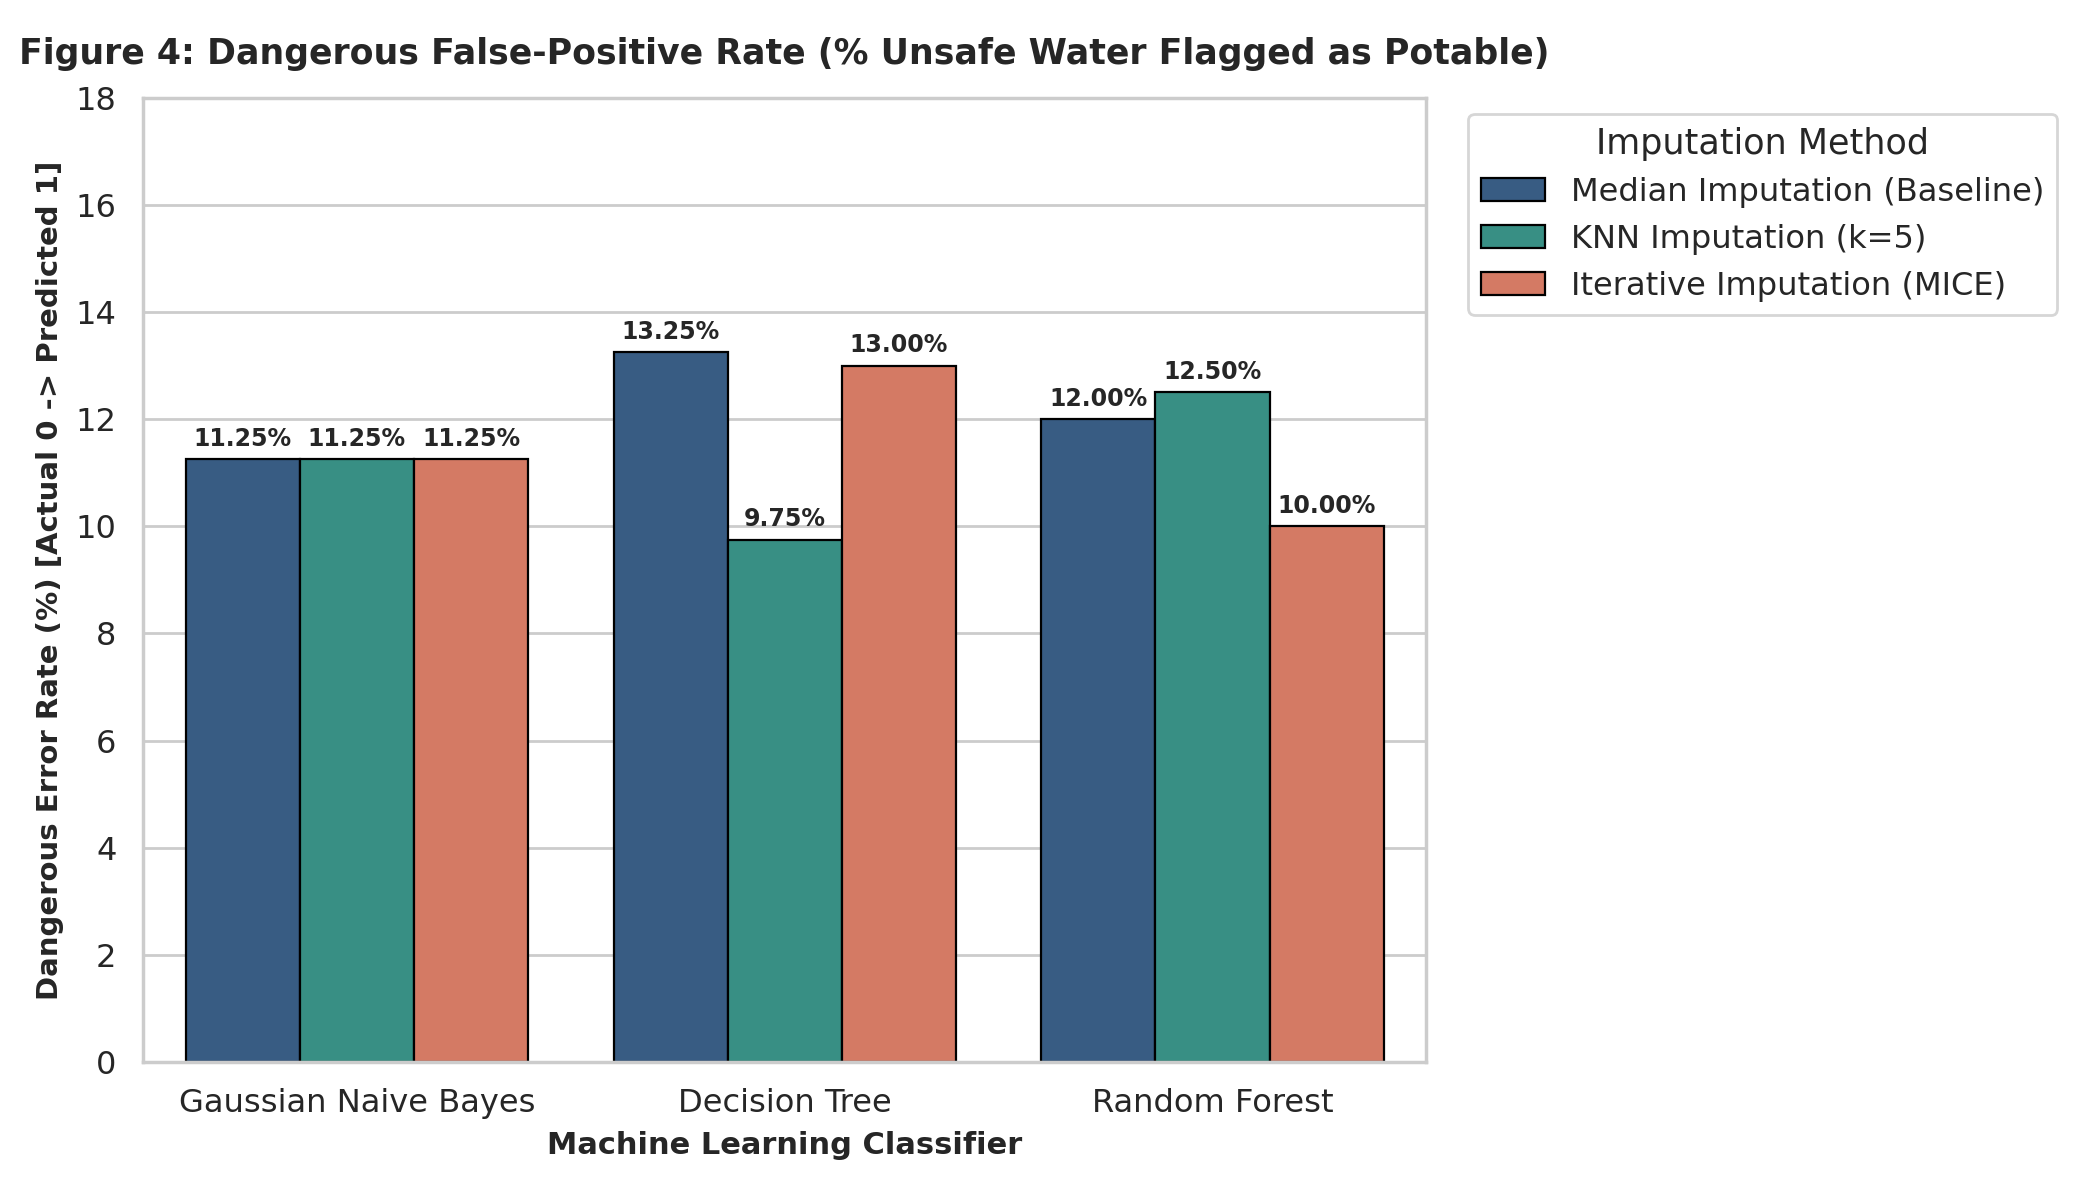

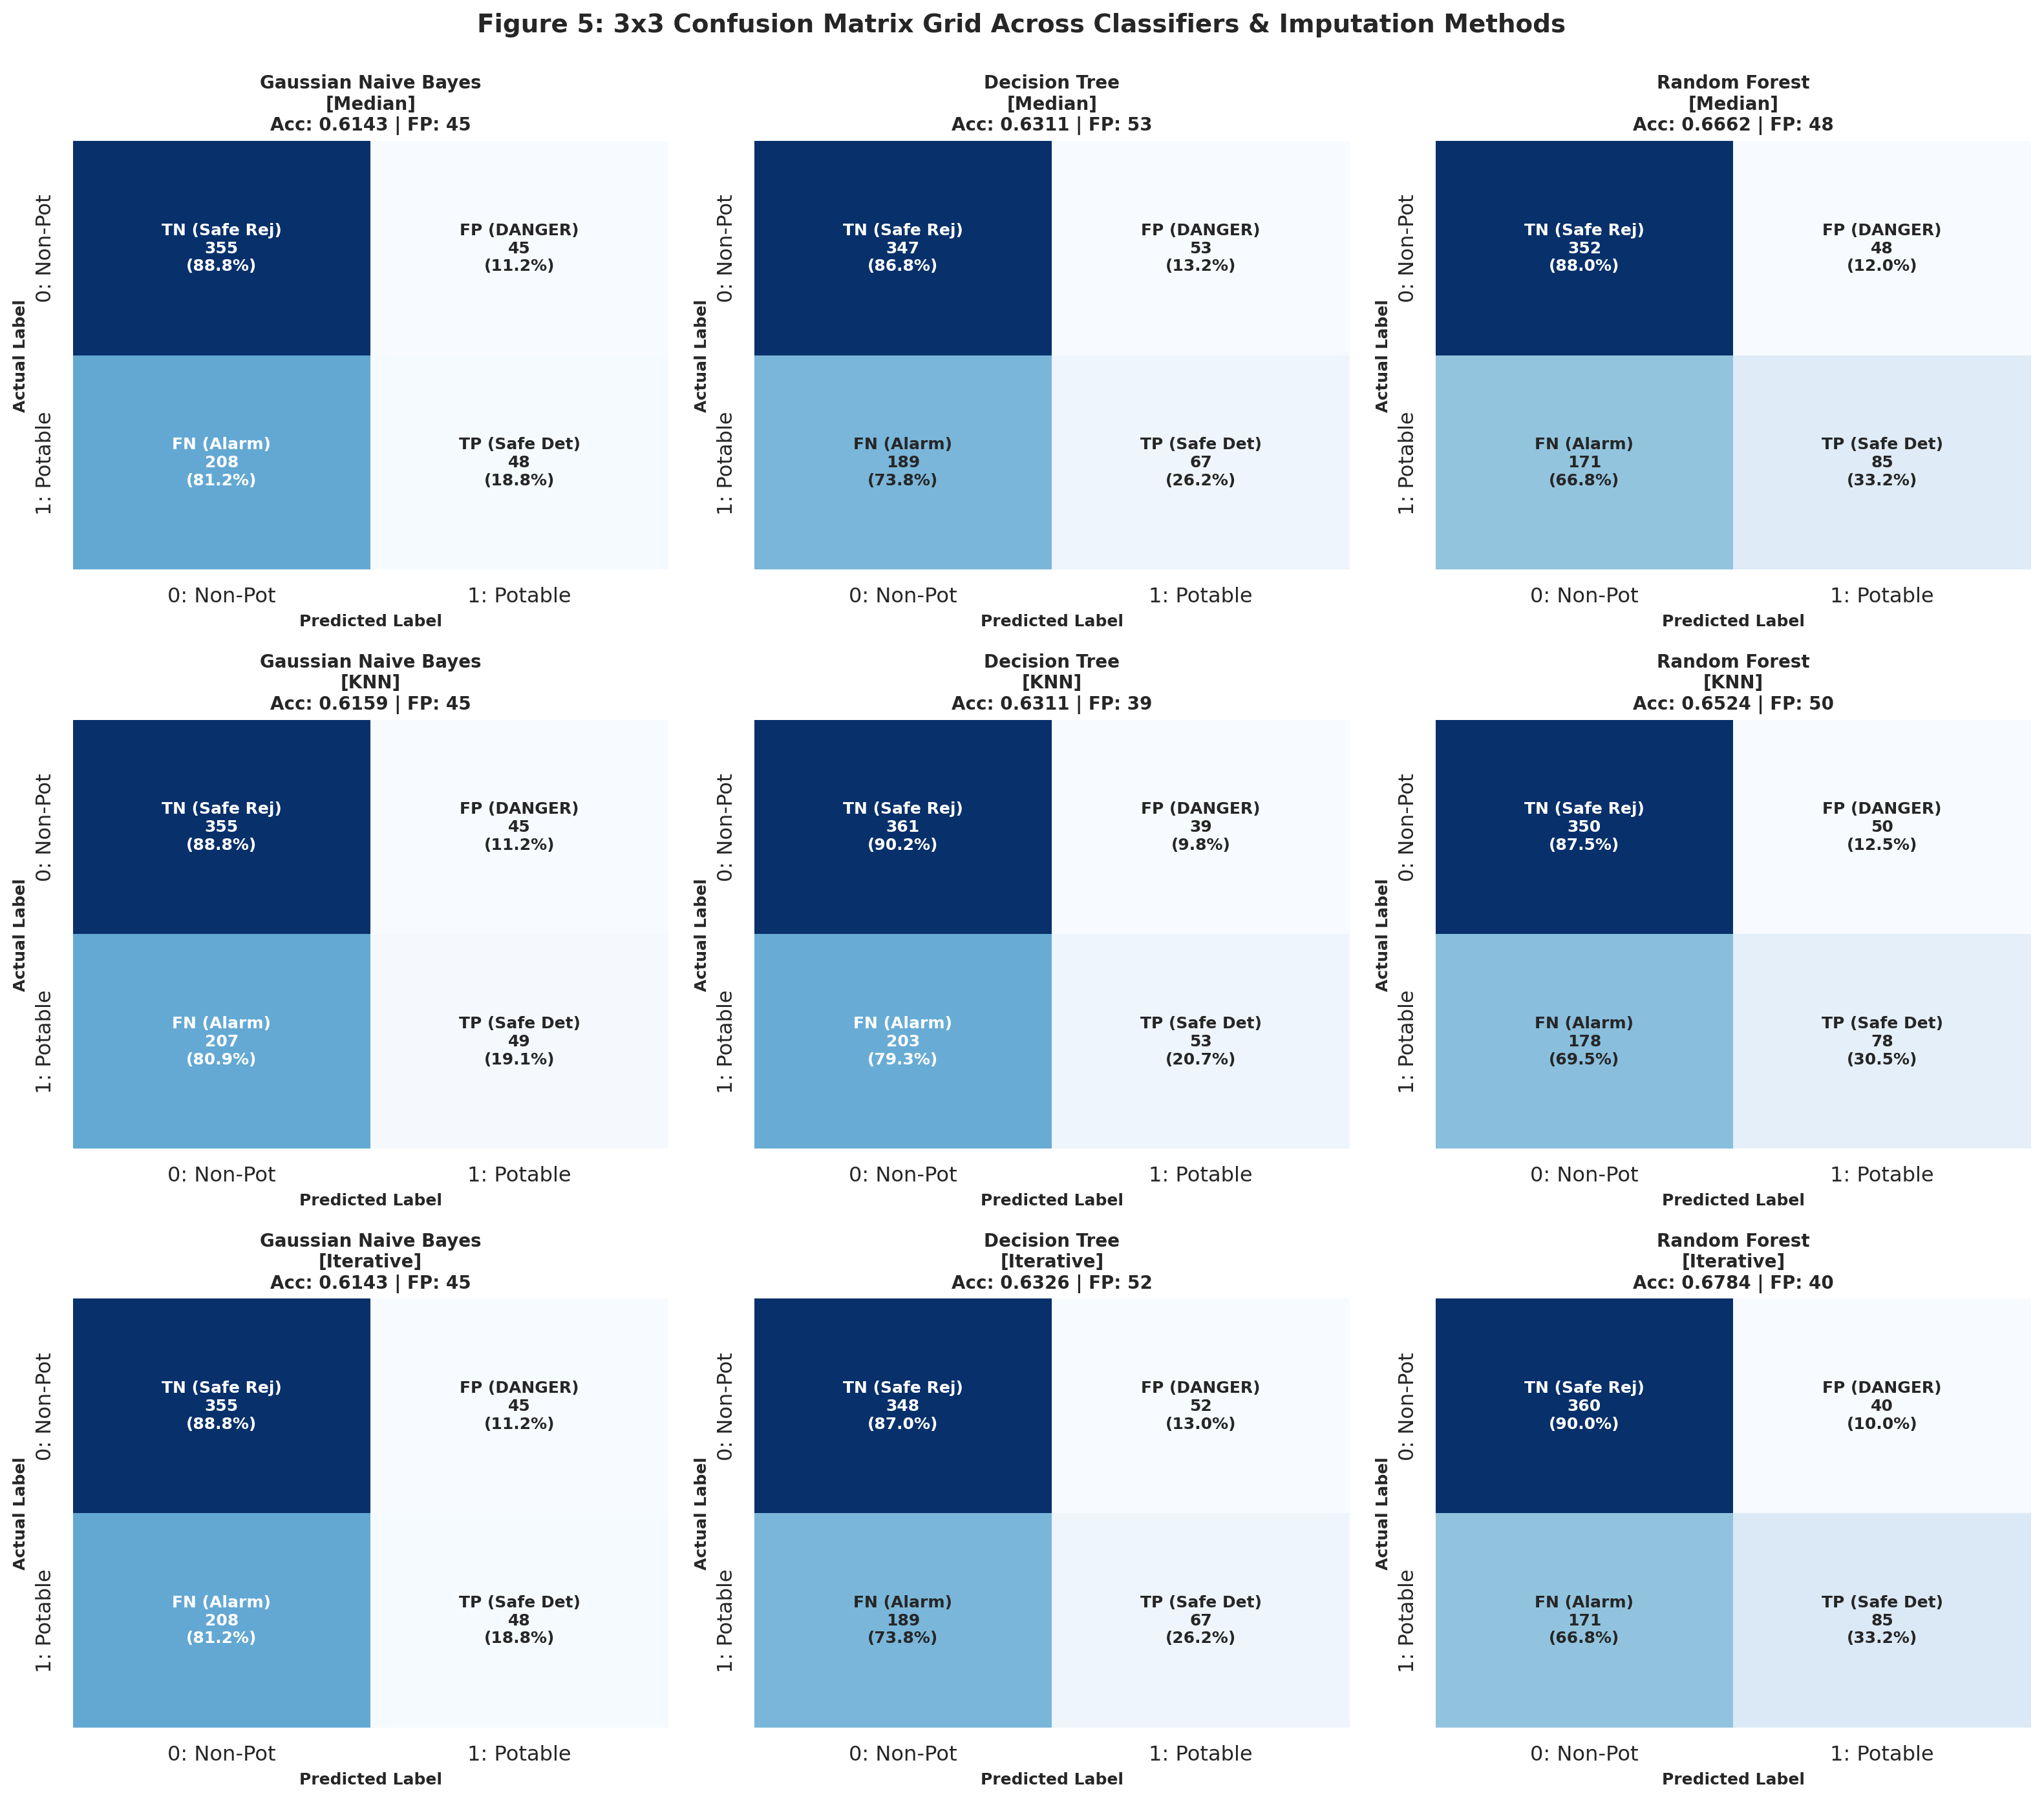

In [18]:
from IPython.display import Image, display

fig_paths = [
    '../results/figures/imputation_accuracy_comparison.png',
    '../results/figures/imputation_f1_comparison.png',
    '../results/figures/imputation_dangerous_error_rate_comparison.png',
    '../results/figures/imputation_best_confusion_matrices.png'
]

for path in fig_paths:
    resolved_path = path if os.path.exists(path) else path.replace('../', '')
    if os.path.exists(resolved_path):
        display(Image(filename=resolved_path))


## Phase 8 Summary: Imputation Comparison Findings

### Complete 3x3 Benchmark Results (Holdout Test Set, n=656)

| Imputation | Classifier | Accuracy | F1-Macro | ROC-AUC | Dangerous FP | FP Rate |
|---|---|---|---|---|---|---|
| Median (Baseline) | Dummy | 0.6098 | 0.3788 | 0.5000 | 0 | 0.00% |
| Median (Baseline) | Gaussian NB | 0.6143 | 0.5062 | 0.6090 | 45 | 11.25% |
| Median (Baseline) | Decision Tree | 0.6311 | 0.5489 | 0.6011 | 53 | 13.25% |
| **Median (Baseline)** | **Random Forest** | **0.6662** | **0.5999** | **0.6492** | 48 | 12.00% |
| KNN (k=5) | Gaussian NB | 0.6159 | 0.5090 | 0.6083 | 45 | 11.25% |
| KNN (k=5) | Decision Tree | 0.6311 | 0.5268 | 0.5852 | **39** | **9.75%** |
| KNN (k=5) | Random Forest | 0.6524 | 0.5803 | **0.6630** | 50 | 12.50% |
| Iterative MICE | Gaussian NB | 0.6143 | 0.5062 | 0.6082 | 45 | 11.25% |
| Iterative MICE | Decision Tree | 0.6326 | 0.5501 | 0.5917 | 52 | 13.00% |
| **Iterative MICE** | **Random Forest** | **0.6784** | **0.6098** | 0.6492 | **40** | **10.00%** |

### Key Findings

**Best Overall:** Iterative MICE + Random Forest — highest accuracy (0.6784), highest F1-Macro (0.6098),  
and lowest Random Forest dangerous FP rate (10.00%).

**Safest Lightweight Option:** KNN Imputation + Decision Tree — lowest dangerous FP rate of any single-tree  
configuration (9.75%, 39 errors; 26.4% reduction vs. Median+DT baseline).

**Best ROC-AUC:** KNN + Random Forest (0.6630) — best probability calibration across all configurations.

**GNB Invariance:** Gaussian Naive Bayes scores are virtually identical regardless of imputation method  
(accuracy range: 0.6143-0.6159), confirming that its conditional independence assumption eliminates any  
benefit from multivariate imputation on this near-zero-correlation dataset.

**Inter-feature correlations |r| < 0.04** limit the leverage of KNN and MICE over Median imputation.  
The modest gains are consistent with the dataset's physicochemical structure.

> Full report: `docs/IMPUTATION_METHOD_COMPARISON.md`  
> Full metrics: `results/metrics/imputation_comparison.csv` (10 rows)  
> Full metrics: `results/metrics/imputation_comparison.json` (10 experiments)
